# 06 · The hydro pair: the wake in the fluid

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhputschke/js-contrib/blob/main/tutorials/pyjetscape/06_hydro_pair.ipynb)

**Time:** 45 minutes · **Needs:** any setup · **Data:** `auau_pair_mini` (streamed, ~40 MB read), `derived` (0.2 MB)

A jet that crosses the quark–gluon plasma loses energy to it. The plasma picks that energy up,
and the fluid responds: a **wake**. The production computes each event twice, once without
the jet and once with the energy the jet deposited. The difference of the two fluids is the
wake and nothing else. This tutorial follows one jet through a central Au+Au collision:
- where the jet deposits its energy, and when;
- what the wake looks like and how it moves through the expanding fluid;
- whether the fluid holds the energy the jet lost;
- how the wake delays the freeze-out.

Reference pages: [Hydro and hadrons together](https://jhputschke.github.io/js-contrib/analysis/hydro-hadrons/), and
[The physics](https://jhputschke.github.io/js-contrib/about/physics/), sections 4–6.

> **The outputs shown** were produced on an Apple Silicon Mac, in the environment the xscape wheel 0.2.0 is built in, with the hydro on the GPU through Metal.

In [1]:
# Setup: the tutorial helpers sit next to this notebook (_common/). In Colab they are
# fetched first, with the jetscape readers; locally nothing is installed.
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.isdir("_common"):
    subprocess.run("curl -sL https://codeload.github.com/jhputschke/js-contrib/tar.gz/refs/heads/main"
                   " | tar xz --strip-components=3 js-contrib-main/tutorials/pyjetscape",
                   shell=True, check=True)
sys.path.insert(0, os.getcwd())
from _common import tutorial_env as te
te.colab_install()
env = te.setup()

tutorials v1.dev | setup: source (runs X-SCAPE; hydro: Metal GPU) | Python 3.13.1 | data: ~/JetScape/X-SCAPE/external_packages/js-contrib/tutorials/pyjetscape/data


## 1. The pair and its grid

`arr` and `arr_bg` hold, for each event, the energy density $e$ and the flow velocity
$(v_x, v_y, v_z)$ on a grid in $x$, $y$, the space-time rapidity $\eta_s$ and the proper time
$\tau$. Each chunk on disk is one event at one $\tau$, so reading a few frames fetches only
those frames. We take event 0, whose jets deposited the most energy (54 GeV), and read the
frames we need once.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

SET, STEM, EVENT = "auau_pair_mini", "AuAu_0_10_jet_seed0101", 0
TAUS = [1.5, 3.0, 5.0, 8.0]                      # fm/c: the frames we look at

with te.h5(SET, STEM + ".h5") as f:
    A = dict(f.attrs)
    x = A["x_min"] + A["dx"] * np.arange(A["nx"])          # cell centres [fm]
    y = A["y_min"] + A["dy"] * np.arange(A["ny"])
    eta = A["eta_min"] + A["deta"] * np.arange(A["neta"])
    frame = lambda tau: int(round((tau - A["tau_min"]) / A["dtau"]))
    jet = {t: f["arr"][EVENT, :, :, :, :, frame(t)] for t in TAUS}      # (4, nx, ny, neta)
    bg = {t: f["arr_bg"][EVENT, :, :, :, :, frame(t)] for t in TAUS}
    o = f["source/offsets"][:]
    droplets = f["source/droplets"][o[EVENT]:o[EVENT + 1]]            # tau, x, y, eta, E, px, py, pz
    oi = f["shower/initiator_offsets"][:]
    ini = f["shower/initiators"][oi[EVENT]:oi[EVENT + 1]]            # shower, pid, pstat, px, py, pz, E, x, y, z, t
    ntau_jet, ntau_bg = f["ntau_freezeout"][EVENT], f["ntau_freezeout_bg"][EVENT]

e_fo = A["edge_e_threshold"]          # e at T_fo = 150 MeV [GeV/fm^3], from MUSIC's EoS
print(f"grid {A['nx']} x {A['ny']} x {A['neta']}, freeze-out at e = {e_fo:.3f} GeV/fm^3")
print(f"frames: jet leg {ntau_jet}, background {ntau_bg}")

grid 64 x 64 x 32, freeze-out at e = 0.243 GeV/fm^3
frames: jet leg 131, background 103


## 2. The jet and where it deposits

The **shower initiators** are the partons from the hard scattering (and the softer ones
PYTHIA adds) that enter the medium. The **droplets** are what the CausalLiquefier made of the
energy and momentum they lost: each droplet is a small source of $(E, \vec p)$ at a point in
space-time, which the fluid absorbs after a delay of 1 fm/c.

In [3]:
import pandas as pd
pt = np.hypot(ini[:, 3], ini[:, 4])
partons = pd.DataFrame({"pid": ini[:, 1].astype(int), "pT [GeV]": pt, "E [GeV]": ini[:, 6],
                        "y": np.arcsinh(ini[:, 5] / pt), "phi": np.arctan2(ini[:, 4], ini[:, 3])})
shower_of = None
print(f"{len(droplets)} droplets, {droplets[:, 4].sum():.1f} GeV in all, created between"
      f" tau = {droplets[:, 0].min():.1f} and {droplets[:, 0].max():.1f} fm/c (the fluid receives each about 1 fm/c later)")
partons.round(2)

24 droplets, 54.1 GeV in all, created between tau = 0.0 and 8.1 fm/c (the fluid receives each about 1 fm/c later)


,pid,pT [GeV],E [GeV],y,phi
0,2,31.92,36.31,-0.52,1.78
1,2,31.60,32.42,-0.23,-1.26
2,21,2.72,5.66,1.36,-1.48
3,21,2.57,3.09,-0.62,0.34
4,2,2.53,14.22,2.41,1.89


The two hardest partons (pid 2: up quarks) leave the hard scattering back to back with
$p_T \approx 32$ GeV, near midrapidity. The others are soft. One of them (the last row) is
at $y = 2.4$: it deposits most of its energy far forward.

The map below shows the background's energy density in the transverse plane, averaged over
$|\eta_s| < 1$, at the start. The arrows show the two hard partons' directions from their
starting point, and the dots are the droplets, sized by their energy.

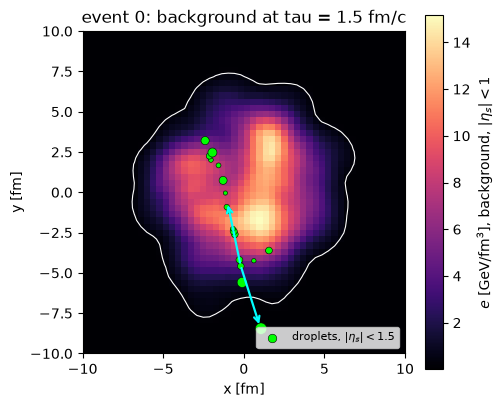

In [4]:
mid = np.abs(eta) < 1.0
fig, ax = plt.subplots(figsize=(5.2, 4.6))
e0 = bg[TAUS[0]][0][:, :, mid].mean(-1)
im = ax.pcolormesh(x, y, e0.T, cmap="magma", shading="nearest")
fig.colorbar(im, ax=ax, label=r"$e$ [GeV/fm$^3$], background, $|\eta_s|<1$")
ax.contour(x, y, e0.T, levels=[e_fo], colors="w", linewidths=0.8)
for row in ini[pt > 10]:
    ax.annotate("", xy=(row[7] + 4 * row[3] / np.hypot(row[3], row[4]), row[8] + 4 * row[4] / np.hypot(row[3], row[4])),
                xytext=(row[7], row[8]), arrowprops=dict(arrowstyle="->", color="cyan", lw=1.6))
near = np.abs(droplets[:, 3]) < 1.5
ax.scatter(droplets[near, 1], droplets[near, 2], s=8 + 8 * np.abs(droplets[near, 4]), c="lime",
           edgecolors="k", linewidths=0.4, label=r"droplets, $|\eta_s| < 1.5$")
ax.set(xlim=(-10, 10), ylim=(-10, 10), xlabel="x [fm]", ylabel="y [fm]", aspect=1,
       title=f"event {EVENT}: background at tau = {TAUS[0]} fm/c")
ax.legend(loc="lower right", fontsize=8);

**What to notice.** The hard scattering happened in the lower part of the fireball, about
3 fm from its edge. One parton heads *out* (down) and leaves the medium after a few fm: its few droplets lie along
its short path. The other heads *in* (up), crosses the whole fireball, and deposits the
largest share, 22 of the 54 GeV. Where a hard scattering happens decides how much medium each parton crosses.
That path length is one of the main reasons jets in the same event lose different amounts
of energy.

## 3. The wake

The wake is $\Delta e = e_\text{jet} - e_\text{bg}$. Both legs started from the same initial
condition, so before the first droplet arrives $\Delta e = 0$ exactly; afterwards it is the
fluid's response to the jet alone. Summed over $|\eta_s| < 1$ and drawn at four times
(red: more energy than without the jet; blue: less):

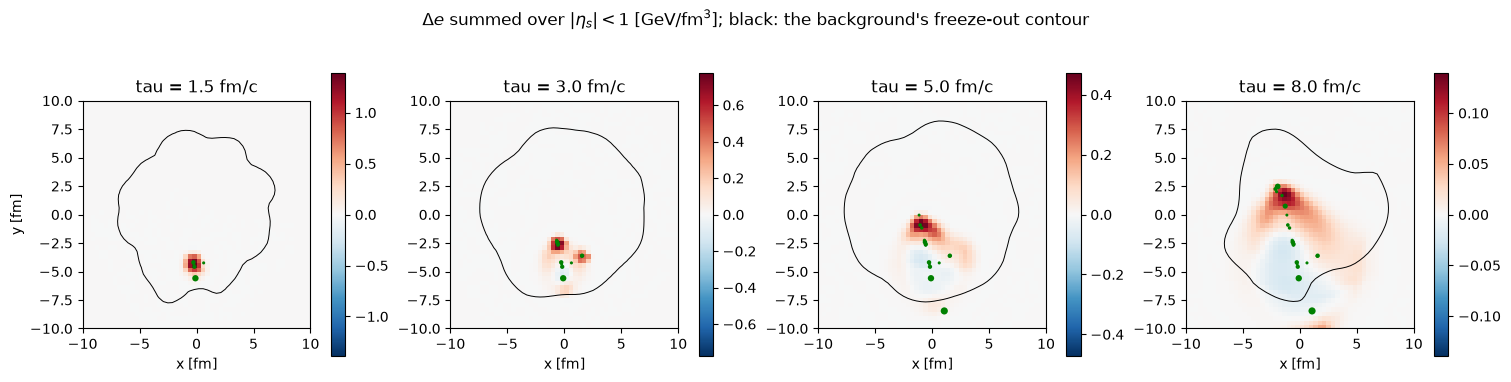

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), constrained_layout=True)
for ax, t in zip(axes, TAUS):
    de = (jet[t][0] - bg[t][0])[:, :, mid].sum(-1) * A["deta"]      # GeV/fm^3, summed over eta_s
    m = np.abs(de).max()
    im = ax.pcolormesh(x, y, de.T, cmap="RdBu_r", vmin=-m, vmax=m, shading="nearest")
    ax.contour(x, y, bg[t][0][:, :, mid].mean(-1).T, levels=[e_fo], colors="k", linewidths=0.7)
    d = droplets[(droplets[:, 0] <= t) & near]
    ax.scatter(d[:, 1], d[:, 2], s=4 + 3 * np.abs(d[:, 4]), c="g", lw=0)
    ax.set(xlim=(-10, 10), ylim=(-10, 10), aspect=1, title=f"tau = {t} fm/c", xlabel="x [fm]")
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[0].set_ylabel("y [fm]")
fig.suptitle(r"$\Delta e$ summed over $|\eta_s|<1$ [GeV/fm$^3$]; black: the background's freeze-out contour");

**What to notice.**

- **Early on, the wake is a hot spot** around each new droplet: the fluid has had no time to
  move yet.
- **Later, it becomes a cone with a depletion behind it.** The jet moves at the speed of
  light, faster than sound in the plasma ($c_s \approx 1/\sqrt 3$). A source moving faster
  than sound drives a **Mach cone**, a front of compressed, hotter fluid at an angle
  $\cos\theta_M = c_s / v$ to its path. The fluid it pushes along leaves less behind it: the
  **diffusion wake**, the blue region along the jet's past path.
- **The expanding fireball carries and distorts the wake.** The background has strong radial
  flow, so the wake drifts outward and does not keep the shape of a cone in a static medium.
- **The scale shrinks quickly** (see the colour bars): the deposited energy spreads over more
  and more fluid, and the whole fireball cools as it expands.

The wake also spreads along $\eta_s$. Summing $\tau\,\Delta e$ over the transverse plane gives its
profile in $\eta_s$ (the local energy per unit $\eta_s$, in the fluid's Bjorken frame):

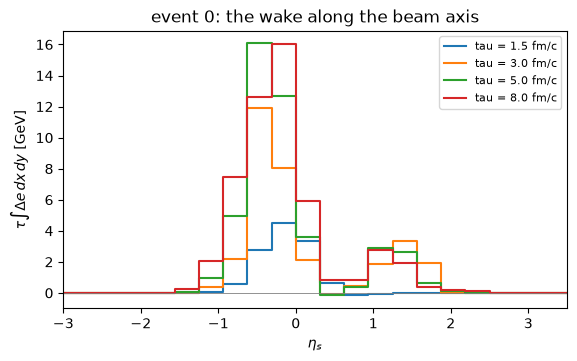

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for t in TAUS:
    prof = t * (jet[t][0] - bg[t][0]).sum((0, 1)) * A["dx"] * A["dy"]
    ax.step(eta, prof, where="mid", label=f"tau = {t} fm/c")
ax.axhline(0, color="0.5", lw=0.6)
ax.set(xlabel=r"$\eta_s$", ylabel=r"$\tau \int \Delta e\, dx\, dy$ [GeV]", xlim=(-3, 3.5),
       title=f"event {EVENT}: the wake along the beam axis")
ax.legend(fontsize=8);

The two hard partons are near midrapidity ($y = -0.5$ and $-0.2$), so most of the wake sits
around $\eta_s \approx -0.5$. It stays narrow in $\eta_s$: the fluid's longitudinal expansion
keeps it close to where it was deposited. The small peak at $\eta_s \approx 1.4$ comes from a
soft parton at $y = 1.4$.

## 4. Does the fluid keep the jet's energy?

The `derived` set holds `wake_observables.h5`, made by `wake_observables.py` from this pair
file. For every $\tau$ frame it has each leg's four-momentum $P^\mu$ through the
$\tau = $ const surface, computed from the ideal-fluid part of the energy–momentum tensor,
$T^{\mu\nu} = (e + P)u^\mu u^\nu - P g^{\mu\nu}$, inside the stored grid. It also has the
four-momentum of all droplets deposited up to that time. If the fluid keeps what the jet
deposits, the difference of the legs, $\Delta P^0 = P^0_\text{jet} - P^0_\text{bg}$, should
follow the droplets' cumulative energy.

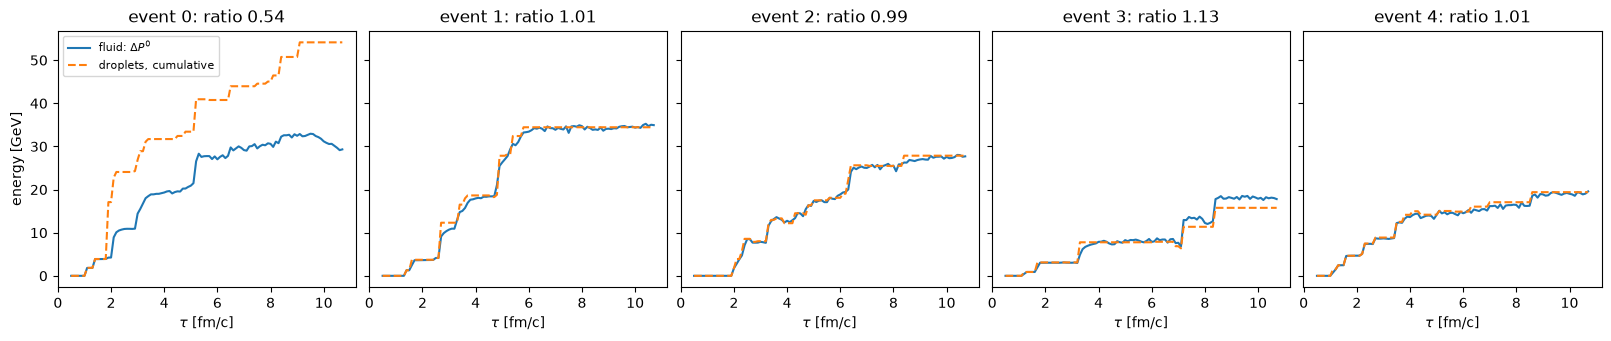

In [7]:
import h5py
with te.h5("derived", "wake_observables.h5") as f:
    P_jet = f["evolution/P_jet"][:]                 # (event, tau frame, E px py pz)
    P_bg = f["evolution/P_bg"][:]
    D = f["evolution/D_inj"][:]                     # cumulative droplet four-momentum
    ev = {k: f["events"][k][:] for k in ["ntau_jet", "ntau_bg", "E_drop", "tau_fo_jet", "tau_fo_bg"]}
    drop = {k: f["droplets"][k][:] for k in ["ev", "tau_dep", "E"]}
tau_frames = A["tau_min"] + A["dtau"] * np.arange(P_jet.shape[1])

fig, axes = plt.subplots(1, 5, figsize=(16, 3.3), sharey=True, constrained_layout=True)
ratio = []
for i, ax in enumerate(axes):
    n = min(ev["ntau_jet"][i], ev["ntau_bg"][i])     # frames where both legs exist
    ax.plot(tau_frames[:n], P_jet[i, :n, 0] - P_bg[i, :n, 0], label=r"fluid: $\Delta P^0$")
    ax.plot(tau_frames[:n], D[i, :n, 0], "--", label="droplets, cumulative")
    ratio.append((P_jet[i, n - 1, 0] - P_bg[i, n - 1, 0]) / D[i, n - 1, 0])
    ax.set(title=f"event {i}: ratio {ratio[-1]:.2f}", xlabel=r"$\tau$ [fm/c]")
axes[0].set_ylabel("energy [GeV]")
axes[0].legend(fontsize=8);

**What to notice.**

- **In four events the fluid holds the deposited energy:** $\Delta P^0$ follows the droplets
  step by step and ends within 15 % of them.
- **Event 0 ends at about half.** The gap opens in two steps. At $\tau \approx 2$ fm/c it
  equals, in energy and in $p_z$, the 13 GeV that the forward parton ($y = 2.4$) deposited at
  $\eta_s = 2.4$, into fluid that moves with $v_z \approx 0.99$ there. From
  $\tau \approx 6$ fm/c on, the leading jet deposits another 13 GeV into fluid near the
  freeze-out temperature, and $\Delta P^0$ grows by only about 5 GeV.
- **This is a check, not an exact conservation law.** The stored grid is smaller than
  MUSIC's, and the viscous part of $T^{\mu\nu}$ is not stored, so neither leg's $P^0$ is
  exactly conserved. Across a campaign, the README of `wake_observables.py` finds
  $\Delta P^0$ / droplets of 0.95–1.06 for most events. An event far outside that range, like
  event 0 here, is one to look at more closely (exercise 3).

## 5. The wake delays the freeze-out

The deposited energy reheats the fluid around the jet, so the jet leg needs longer to cool
below $T_\text{fo}$. Is it the total energy that matters, or when it was deposited?

delays [fm/c]: [2.8 0.  0.6 2.  1.1] | late deposits [GeV]: [13.4  0.   9.8  8.   4.5]


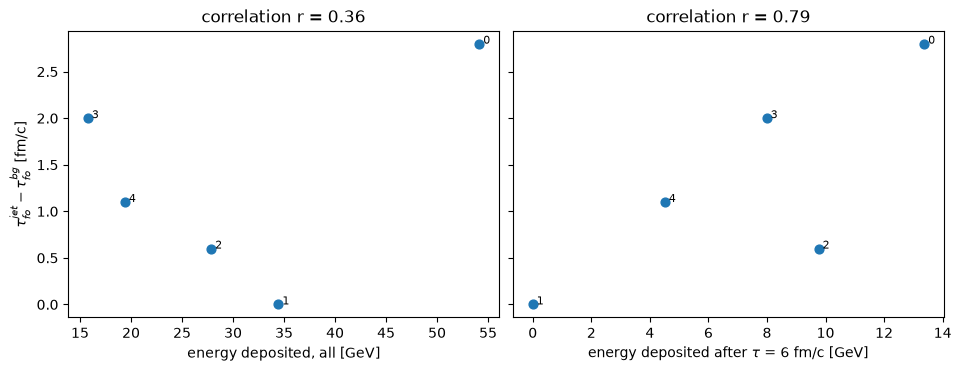

In [8]:
delay = ev["tau_fo_jet"] - ev["tau_fo_bg"]
E_late = np.array([drop["E"][(drop["ev"] == i) & (drop["tau_dep"] > 6)].sum() for i in range(len(delay))])

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True, constrained_layout=True)
for ax, E, label in [(axes[0], ev["E_drop"], "energy deposited, all [GeV]"),
                     (axes[1], E_late, r"energy deposited after $\tau$ = 6 fm/c [GeV]")]:
    ax.scatter(E, delay, s=40)
    for i in range(len(delay)):
        ax.annotate(f" {i}", (E[i], delay[i]), fontsize=8)
    ax.set(xlabel=label, title=f"correlation r = {np.corrcoef(E, delay)[0, 1]:.2f}")
axes[0].set_ylabel(r"$\tau_{fo}^{jet} - \tau_{fo}^{bg}$ [fm/c]")
print("delays [fm/c]:", np.round(delay, 1), "| late deposits [GeV]:", np.round(E_late, 1))

**What to notice.** The delay follows the energy deposited **late** much more closely than
the total. Event 1 deposited 34 GeV, all of it before $\tau = 5.7$ fm/c, and its jet leg
freezes out together with the background: energy deposited early, into hot fluid, spreads
out and cools with the rest of the fireball. Event 3 deposited only 16 GeV, but half of it
after 6 fm/c, into fluid already near $T_\text{fo}$: a small reheated region then outlives
the background by 2 fm/c. With five events this is an illustration, not a measurement.

The hadrons from the jet leg's surface carry this extra energy: that is the hadronic wake of
tutorial 07.

### Check your result

In [9]:
import json
exp = json.load(open("expected/06_hydro_pair.json"))
de5 = (jet[5.0][0] - bg[5.0][0])[:, :, mid].sum(-1) * A["deta"]
np.testing.assert_allclose([de5.max(), de5.min()], exp["de_tau5_max_min"], rtol=1e-4)
np.testing.assert_allclose(ratio, exp["ratio_dP0_droplets"], rtol=1e-4)
np.testing.assert_allclose(delay, exp["freezeout_delay"], atol=1e-6)
print("All checks pass.")

All checks pass.


## Exercises

1. **The Mach angle.** In the $\tau = 8$ fm/c map, estimate the opening angle of the front
   relative to the jet's direction. Compare it with $\cos\theta_M = c_s$ for $c_s^2 = 1/3$,
   and think about why the expanding, flowing background changes it.
2. **Another event.** Set `EVENT = 3` (16 GeV deposited, the smallest) and rerun the
   notebook. How do the wake's size and the freeze-out delay compare with event 0?
3. **Event 0's energy.** Plot $\Delta P^z$ (column 3) against the droplets' cumulative $p_z$
   for event 0, and find the frame where the gap opens. Read the droplets of that time from
   `source/droplets` and look at their $\eta_s$ and energy. Then look at the wake along
   $\eta_s$ at $\tau = 2.5$ fm/c around $\eta_s = 2.4$.
4. **The flow of the wake.** The velocity is in channels 1–3. Plot the momentum density of
   the wake, $\Delta(e\,\vec v_\perp)$ (approximately), as arrows (`plt.quiver`) on the
   $\tau = 5$ fm/c map. Which way does the fluid in the depletion move?

## Next steps

- The same wake in hadrons: tutorial 07.
- The campaign-level analysis of the wake: `analysis/wake_observables.py` and its notebook ([Hydro and hadrons together](https://jhputschke.github.io/js-contrib/analysis/hydro-hadrons/#3-the-wake-in-the-fluid-for-a-whole-campaign)).
- Movies of the wake in 3D: [3D visualization](https://jhputschke.github.io/js-contrib/python/visualization/) and tutorial 15.
- How the droplets reach the fluid: [The physics](https://jhputschke.github.io/js-contrib/about/physics/), section 5.